# Midterm 1 – Credit Card Default Prediction
**FI510E – AI & Business Applications** | Group: Lucas Clodic, Elisa Ouillet, Iulia Kozhina

Dataset: Default of Credit Card Clients (UCI) – https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients

**Business problem.** A bank wants to know which credit card clients will not pay their bill next month (default).
The collections team cannot call everybody: it can contact around 10% of the clients per month. So we need a model
that ranks clients by risk, and the team calls the most risky ones first.

Positive class = **default next month (1)**.

| Outcome | Meaning |
|---|---|
| TP | defaulter correctly flagged → we can call him early |
| FP | good client flagged → useless call, cost + annoyed client |
| FN | defaulter missed → loss for the bank |
| TN | good client not flagged |

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Task 1 – Inspect the data and default patterns
The data file is `data/default_of_credit_card_clients.xls` in the repository (no need to move it).
In Colab: either clone the repository or upload the `.xls` file next to the notebook. The first row of the file is a second header, so we use `header=1`.

In [2]:
%pip install xlrd


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /Users/lucas/Documents/RBS/AI/.venvs/midterm1/bin/python3.14 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [3]:
# Look for the file in the usual places, so the notebook runs on any computer without editing a path
file_name = 'default_of_credit_card_clients.xls'
candidates = [
    os.path.join('..', 'data', file_name),                          # notebook opened from notebooks/ (Jupyter)
    os.path.join('data', file_name),                                # run from the repository root
    os.path.join('Midterm1_AI_Applications', 'data', file_name),    # Colab after git clone
    file_name,                                                      # Colab after uploading the file
]
path = next((p for p in candidates if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError(f'{file_name} not found. Put it in data/ or next to this notebook. '
                            'Source: https://archive.ics.uci.edu/dataset/350')
print('data file:', path)

clients = pd.read_excel(path, header=1)
clients = clients.rename(columns={'default payment next month': 'default'})

print(clients.shape)
print(clients['default'].value_counts())
print(clients['default'].mean())

data file: ../data/default_of_credit_card_clients.xls


/var/folders/9s/m40t53rj231d1wd5qt3nkhh00000gn/T/ipykernel_90121/1602558216.py:15: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  clients = pd.read_excel(path, header=1)


(30000, 25)
default
0    23364
1     6636
Name: count, dtype: int64
0.2212


In [4]:
clients.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


22% of clients defaulted. A model that always says "no default" already has 78% accuracy, so accuracy will not be enough to compare models.

### Data quality checks

In [5]:
print('missing values:', clients.isna().sum().sum())
print('duplicated rows (without ID):', clients.drop(columns='ID').duplicated().sum())
print('EDUCATION:', clients['EDUCATION'].value_counts().sort_index().to_dict())
print('MARRIAGE:', clients['MARRIAGE'].value_counts().sort_index().to_dict())
print('PAY_0:', clients['PAY_0'].value_counts().sort_index().to_dict())

bill_cols = ['BILL_AMT1','BILL_AMT2','BILL_AMT3','BILL_AMT4','BILL_AMT5','BILL_AMT6']
print('clients with a negative bill:', (clients[bill_cols] < 0).any(axis=1).sum())

missing values: 0
duplicated rows (without ID): 35
EDUCATION: {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE: {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_0: {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}
clients with a negative bill: 1930


Problems we found:
- **EDUCATION** has codes 0, 5, 6 and **MARRIAGE** has code 0 that are not explained in the data description → we put them in "other" (4 for education, 3 for marriage).
- **PAY_x** uses -2 and 0, which are also not in the official description. From other projects: -2 = no balance, -1 = paid in full, 0 = paid the minimum, 1–8 = months of delay.
- 1,930 clients have a negative bill (they paid too much, credit balance) → we keep them, it is real.
- 35 duplicated rows, mostly inactive accounts with all bills = 0 → we keep them, they can be different clients.
- No missing values.

In [6]:
clients['EDUCATION'] = clients['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
clients['MARRIAGE'] = clients['MARRIAGE'].replace({0: 3})

In [7]:
# default rate by the status of the last month (September)
print(clients.groupby(clients['PAY_0'].clip(upper=3))['default'].mean())

print(clients.groupby('SEX')['default'].mean())        # 1 = male, 2 = female
print(clients.groupby('EDUCATION')['default'].mean())
print(clients.groupby('MARRIAGE')['default'].mean())

PAY_0
-2    0.132294
-1    0.167781
 0    0.128113
 1    0.339479
 2    0.691414
 3    0.719222
Name: default, dtype: float64
SEX
1    0.241672
2    0.207763
Name: default, dtype: float64
EDUCATION
1    0.192348
2    0.237349
3    0.251576
4    0.070513
Name: default, dtype: float64
MARRIAGE
1    0.234717
2    0.209283
3    0.236074
Name: default, dtype: float64


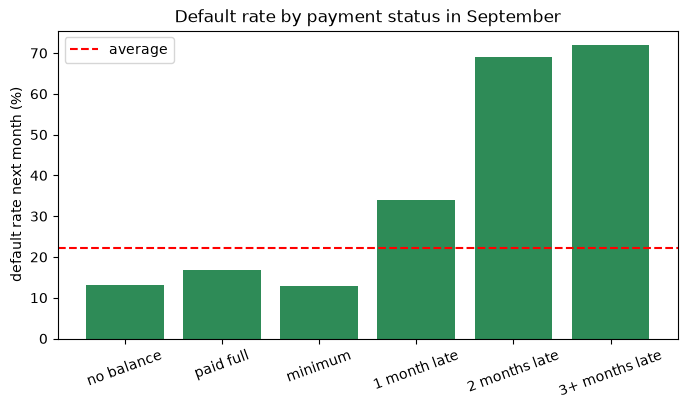

In [8]:
rate = clients.groupby(clients['PAY_0'].clip(upper=3))['default'].mean() * 100
labels = ['no balance', 'paid full', 'minimum', '1 month late', '2 months late', '3+ months late']

plt.figure(figsize=(8, 4))
plt.bar(labels, rate.values, color='seagreen')
plt.axhline(clients['default'].mean() * 100, color='red', linestyle='--', label='average')
plt.ylabel('default rate next month (%)')
plt.title('Default rate by payment status in September')
plt.xticks(rotation=20)
plt.legend()
plt.show()

Clients who were already 2 months late in September defaulted 69% of the time, compared to around 13% for clients who pay normally.
Men default a bit more than women (24% vs 21%), and university / high school more than graduate school.

These differences do not prove cause and effect. Being late does not *cause* the default: both can come from something we do not see in the data, for example losing a job or illness.
And for sex or marital status it would be wrong (and illegal in many countries) to say "being a man causes default".

## Task 2 – Features and data split

We also create some new variables (ratios) that a credit analyst would look at. This is one of our improvements.

In [9]:
pay_status = ['PAY_0','PAY_2','PAY_3','PAY_4','PAY_5','PAY_6']
pay_amt = ['PAY_AMT1','PAY_AMT2','PAY_AMT3','PAY_AMT4','PAY_AMT5','PAY_AMT6']

limit = clients['LIMIT_BAL'].clip(lower=1)

# how much of the credit limit is used
clients['UTIL_LAST'] = (clients['BILL_AMT1'] / limit).clip(-1, 3)
clients['UTIL_AVG'] = (clients[bill_cols].mean(axis=1) / limit).clip(-1, 3)

# how much of the previous bills was paid (PAY_AMT1 in September pays the August bill BILL_AMT2)
paid = clients[pay_amt[:5]].sum(axis=1)
owed = clients[bill_cols[1:]].clip(lower=0).sum(axis=1)
ratio = paid / owed.where(owed > 0, 1)
clients['PAY_RATIO'] = ratio.where(owed > 0, 1.0).clip(0, 2)

# payment behaviour
clients['MONTHS_LATE'] = (clients[pay_status] > 0).sum(axis=1)
clients['MAX_DELAY'] = clients[pay_status].max(axis=1).clip(lower=0)
clients['BILL_TREND'] = ((clients['BILL_AMT1'] - clients['BILL_AMT6']) / limit).clip(-3, 3)
clients['ZERO_PAY_MONTHS'] = ((clients[pay_amt].values == 0) & (clients[bill_cols].values > 0)).sum(axis=1)

new_cols = ['UTIL_LAST','UTIL_AVG','PAY_RATIO','MONTHS_LATE','MAX_DELAY','BILL_TREND','ZERO_PAY_MONTHS']
clients[new_cols].describe().round(2)

,UTIL_LAST,UTIL_AVG,PAY_RATIO,MONTHS_LATE,MAX_DELAY,BILL_TREND,ZERO_PAY_MONTHS
count,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00
mean,0.42,0.37,0.40,0.83,0.68,0.11,0.69
std,0.41,0.35,0.43,1.55,1.07,0.30,0.99
min,-0.62,-0.23,0.00,0.00,0.00,-1.83,0.00
25%,0.02,0.03,0.05,0.00,0.00,-0.03,0.00
50%,0.31,0.28,0.12,0.00,0.00,0.01,0.00
75%,0.83,0.69,0.94,1.00,2.00,0.18,1.00
max,3.00,3.00,2.00,6.00,8.00,3.00,6.00


In [10]:
raw_number_cols = ['LIMIT_BAL'] + pay_status + bill_cols + pay_amt
number_cols = raw_number_cols + new_cols
category_cols = ['EDUCATION']
features = number_cols + category_cols
print(len(features), 'features')

27 features


**Approved feature list:** credit limit, education, the 6 payment statuses, the 6 bills, the 6 payments and our 7 new ratios.

**Excluded:**
- `ID` – only an identifier, it is used in the final file but not as an input.
- `default` – it is the target, known only next month.
- `SEX`, `MARRIAGE`, `AGE` – protected attributes. Using them for a credit decision is discrimination. In Task 6 we check how much accuracy we lose without them.

All inputs are from April–September 2005, so they are known before the October payment → no information from the future.

**Split.** In the lab we sorted by time. Here there is no date per client: all clients are observed at the same moment (the 6 months are inside the columns).
So we cannot do a chronological split. We use a random split with `stratify` so that train, validation and test all have 22% of defaults:
70% train (21,000), 15% validation (4,500) for choosing the model, 15% test (4,500) used only once at the end.

In [11]:
from sklearn.model_selection import train_test_split

train, temp = train_test_split(clients, test_size=0.30, stratify=clients['default'], random_state=42)
valid, test = train_test_split(temp, test_size=0.50, stratify=temp['default'], random_state=42)

print(train.shape, valid.shape, test.shape)
print(train['default'].mean(), valid['default'].mean(), test['default'].mean())

(21000, 32) (4500, 32) (4500, 32)
0.2211904761904762 0.22111111111111112 0.22133333333333333


## Task 3 – Train five models on the same observations
Same five methods as in the lab. Scaling and one-hot encoding are fitted only on the training data (inside the Pipeline).

In [12]:
import sys
!"{sys.executable}" -m pip install xgboost


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /Users/lucas/Documents/RBS/AI/.venvs/midterm1/bin/python3.14 -m pip install --upgrade pip


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

methods = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=20,
                                            n_jobs=-1, random_state=42),
    'Support Vector Machine': SVC(kernel='rbf', C=1.0, gamma='scale', probability=True,
                                  cache_size=1000, random_state=42),
    'Extreme Gradient Boosting': XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                               subsample=0.8, colsample_bytree=0.8,
                                               eval_metric='logloss', random_state=42),
}

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

prepare = ColumnTransformer([
    ('numbers', StandardScaler(), number_cols),
    ('categories', OneHotEncoder(handle_unknown='ignore', sparse_output=False), category_cols)
])

models = {}
for name, algorithm in methods.items():
    model = Pipeline([('prepare', prepare), ('model', algorithm)])
    model.fit(train[features], train['default'])
    models[name] = model
    print(name, 'trained')
# the SVM takes about 1-2 minutes

Logistic Regression trained
Decision Tree trained


Random Forest trained


Support Vector Machine trained


Extreme Gradient Boosting trained


In [15]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score)

y_valid = valid['default'].values
valid_scores = {}
results = []

for name, model in models.items():
    risk_scores = model.predict_proba(valid[features])[:, 1]
    valid_scores[name] = risk_scores
    predicted = (risk_scores >= 0.50).astype(int)
    results.append({
        'Method': name,
        'Accuracy': accuracy_score(y_valid, predicted),
        'Precision': precision_score(y_valid, predicted),
        'Recall': recall_score(y_valid, predicted),
        'F1-score': f1_score(y_valid, predicted),
        'Alerts': predicted.sum(),
        'Missed defaults (FN)': ((predicted == 0) & (y_valid == 1)).sum(),
        'False alerts (FP)': ((predicted == 1) & (y_valid == 0)).sum(),
        'Average Precision': average_precision_score(y_valid, risk_scores),
        'ROC-AUC': roc_auc_score(y_valid, risk_scores),
    })

table_050 = pd.DataFrame(results).set_index('Method')
table_050.round(3)

,Accuracy,Precision,Recall,F1-score,Alerts,Missed defaults (FN),False alerts (FP),Average Precision,ROC-AUC
Method,,,,,,,,,
Logistic Regression,0.811,0.659,0.304,0.416,458,693,156,0.512,0.755
Decision Tree,0.813,0.636,0.358,0.458,560,639,204,0.512,0.764
Random Forest,0.814,0.648,0.348,0.453,534,649,188,0.552,0.777
Support Vector Machine,0.814,0.662,0.321,0.432,482,676,163,0.497,0.715
Extreme Gradient Boosting,0.817,0.660,0.356,0.462,536,641,182,0.550,0.779


**Business interpretation.**
- The model that misses the fewest defaulters is the **Decision Tree** (recall 0.358, 639 missed).
- The model with the fewest false alerts is **Logistic Regression** (156 false alerts).
- The highest accuracy is **XGBoost** with 81.7%, but this is only 3.8 points more than the "nobody defaults" model (77.9%).
  At the 0.50 threshold all models miss more than 64% of the defaulters. So accuracy is not a good way to choose a model for default detection.
  We look at **Average Precision** (quality of the whole ranking) instead.

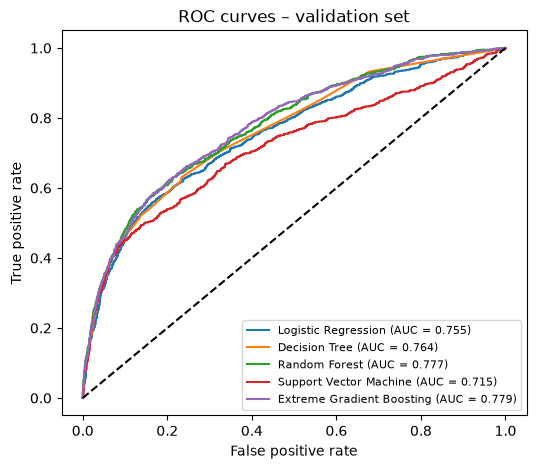

In [16]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(6, 5))
for name, risk_scores in valid_scores.items():
    fpr, tpr, _ = roc_curve(y_valid, risk_scores)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_valid, risk_scores):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curves – validation set')
plt.legend(fontsize=8)
plt.show()

## Task 4 – Rank the validation clients (capacity = 450 calls)
The team can call 10% of the clients → 450 out of the 4,500 validation clients. For each model we take the 450 highest risk scores.

In [17]:
capacity = 450
rows = []
for name, risk_scores in valid_scores.items():
    selected_rows = np.argsort(-risk_scores, kind='stable')[:capacity]
    found = y_valid[selected_rows].sum()
    rows.append({
        'Method': name,
        'Real defaulters found': found,
        'False alerts': capacity - found,
        'Precision at 450': found / capacity,
        'Recall at 450': found / y_valid.sum(),
        'Average Precision': average_precision_score(y_valid, risk_scores),
    })

table_top = pd.DataFrame(rows).set_index('Method')

# Selection rule fixed BEFORE looking at the test set: highest validation Average Precision
# (tie-break: precision at 450). Same rule as src/train.py, so notebook and website use the same model.
# Near-tie rule: a gap below 0.005 AP is noise (XGBoost's AP moved by 0.004 between two of our laptops),
# so among near-tied models we keep one whose result does not depend on the computer.
tie_margin = 0.005
machine_dependent = {'Extreme Gradient Boosting'}
ranking = table_top.sort_values(['Average Precision', 'Precision at 450'], ascending=False)
near_best = [m for m in ranking.index
             if ranking.loc[m, 'Average Precision'] >= ranking['Average Precision'].iloc[0] - tie_margin]
stable = [m for m in near_best if m not in machine_dependent]
best_model = stable[0] if stable else ranking.index[0]
print('Near-tie (within 0.005 AP):', near_best)
print('Selected model:', best_model)
table_top.round(3)

Near-tie (within 0.005 AP): ['Random Forest', 'Extreme Gradient Boosting']
Selected model: Random Forest


,Real defaulters found,False alerts,Precision at 450,Recall at 450,Average Precision
Method,,,,,
Logistic Regression,298,152,0.662,0.299,0.512
Decision Tree,307,143,0.682,0.309,0.512
Random Forest,310,140,0.689,0.312,0.552
Support Vector Machine,304,146,0.676,0.306,0.497
Extreme Gradient Boosting,310,140,0.689,0.312,0.550


In [18]:
print('random calls would find about', round(capacity * y_valid.mean()), 'defaulters')

random calls would find about 100 defaulters


**Candidate model.** If we call 450 random clients we find only ~100 defaulters. All models find around 3 times more.
Random Forest and XGBoost both find 310 defaulters (140 useless calls) and their Average Precision is almost the same (0.552 vs 0.550).

Our rule, decided before the test: highest **Average Precision**, and if two models are within **0.005** of each other we treat it as a tie
and keep the model whose result does not depend on the computer. Why this second part: when two of us ran exactly the same notebook,
with the same library versions, XGBoost got 0.554 on one laptop and 0.550 on the other, while Random Forest stayed at 0.552.
So the difference between the two is noise, and a bank does not want its contact list to change just because the model was retrained on another server.
→ **Random Forest** is our candidate. XGBoost remains an equivalent alternative.


## Task 5 – Threshold trade-off

In [19]:
for name in dict.fromkeys(['Support Vector Machine', 'Extreme Gradient Boosting', 'Random Forest', best_model]):
    print(name)
    risk_scores = valid_scores[name]
    for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
        predicted = (risk_scores >= threshold).astype(int)
        print('  ', threshold, int(predicted.sum()))

Support Vector Machine
   0.2 705
   0.3 581
   0.4 527
   0.5 482
   0.6 412
   0.7 310
Extreme Gradient Boosting
   0.2 1543
   0.3 997
   0.4 693
   0.5 536
   0.6 433
   0.7 268
Random Forest
   0.2 1550
   0.3 1017
   0.4 695
   0.5 534
   0.6 401
   0.7 182


With 0.50 all models give more than 450 alerts (482–534). The first threshold that stays under 450 is **0.60** (401 alerts for Random Forest, 433 for XGBoost, 412 for SVM).

But a threshold gives a different number of alerts every month: if the economy is bad, all scores go up and the team gets too many cases.
"Call the 450 highest scores" always gives exactly 450 calls, so with a strict limit this rule is easier to use. We keep the **top-450 rule**.

## Task 6 – Our improvements (innovation)

### 6a. Do our new ratios help?
We train the models again with only the raw columns (no ratios) and compare. We skip the SVM here because it is too slow.

In [20]:
from sklearn.base import clone   # clone = a fresh copy, so we do not overwrite our trained models

fast_models = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Extreme Gradient Boosting']

prepare_raw = ColumnTransformer([
    ('numbers', StandardScaler(), raw_number_cols),
    ('categories', OneHotEncoder(handle_unknown='ignore', sparse_output=False), category_cols)
])

rows = []
for name in fast_models:
    model_raw = Pipeline([('prepare', prepare_raw), ('model', clone(methods[name]))])
    model_raw.fit(train[raw_number_cols + category_cols], train['default'])
    s = model_raw.predict_proba(valid[raw_number_cols + category_cols])[:, 1]
    rows.append({'Method': name,
                 'AUC raw': roc_auc_score(y_valid, s),
                 'AUC with our ratios': table_050.loc[name, 'ROC-AUC']})

fe_table = pd.DataFrame(rows).set_index('Method')
fe_table['gain'] = fe_table['AUC with our ratios'] - fe_table['AUC raw']
fe_table.round(4)

,AUC raw,AUC with our ratios,gain
Method,,,
Logistic Regression,0.7130,0.7552,0.0422
Decision Tree,0.7417,0.7640,0.0223
Random Forest,0.7749,0.7773,0.0024
Extreme Gradient Boosting,0.7758,0.7793,0.0035


The ratios help all models. The biggest gain is for Logistic Regression (+0.042 AUC, from 0.713 to 0.755), which is the easiest model to explain to a manager.
Random Forest and XGBoost gain less because trees can find these relations alone.

### 6b. Fairness: what do we lose without SEX, MARRIAGE and AGE?

In [21]:
number_with_age = ['LIMIT_BAL', 'AGE'] + pay_status + bill_cols + pay_amt + new_cols
category_all = ['SEX', 'EDUCATION', 'MARRIAGE']

prepare_all = ColumnTransformer([
    ('numbers', StandardScaler(), number_with_age),
    ('categories', OneHotEncoder(handle_unknown='ignore', sparse_output=False), category_all)
])

rows = []
for name in fast_models:
    model_all = Pipeline([('prepare', prepare_all), ('model', clone(methods[name]))])
    model_all.fit(train[number_with_age + category_all], train['default'])
    s = model_all.predict_proba(valid[number_with_age + category_all])[:, 1]
    rows.append({'Method': name,
                 'AUC with sensitive': roc_auc_score(y_valid, s),
                 'AUC without (our model)': table_050.loc[name, 'ROC-AUC']})

fair_table = pd.DataFrame(rows).set_index('Method')
fair_table['difference'] = fair_table['AUC with sensitive'] - fair_table['AUC without (our model)']
fair_table.round(4)

,AUC with sensitive,AUC without (our model),difference
Method,,,
Logistic Regression,0.7542,0.7552,-0.0010
Decision Tree,0.7645,0.7640,0.0005
Random Forest,0.7788,0.7773,0.0015
Extreme Gradient Boosting,0.7813,0.7793,0.0020


In [22]:
# who is on the contact list of the selected model? (sex is NOT used by the model)
selected_rows = np.argsort(-valid_scores[best_model], kind='stable')[:capacity]
contact_list = valid.iloc[selected_rows]

print('women in the portfolio:  ', round((valid['SEX'] == 2).mean(), 3))
print('women among defaulters:  ', round((valid[valid['default'] == 1]['SEX'] == 2).mean(), 3))
print('women in the contact list:', round((contact_list['SEX'] == 2).mean(), 3))
print(contact_list.groupby('SEX')['default'].mean())   # hit rate for men (1) and women (2)

women in the portfolio:   0.601
women among defaulters:   0.596
women in the contact list: 0.582
SEX
1    0.691489
2    0.687023
Name: default, dtype: float64


Without the sensitive variables we lose at most 0.002 AUC, which is almost nothing. The contact list has 58% women, very close to the 60% of women among the real defaulters,
and the hit rate is the same for men and women (about 69%). So we keep the model **without** SEX, MARRIAGE and AGE.

### 6c. Cost–benefit: how many clients should we call?
Our assumptions (to check with the finance team):
- one call costs **500 NT$**
- calling a good client costs **1,500 NT$ more** (annoyed client, risk that he leaves the bank)
- calling a future defaulter early saves **10% of his bill** (`BILL_AMT1`)

In [23]:
contact_cost = 500
false_alarm_cost = 1500
recovery_rate = 0.10

risk_scores = valid_scores[best_model]
order = np.argsort(-risk_scores, kind='stable')
exposure = valid['BILL_AMT1'].clip(lower=0).values

k_values = np.arange(50, len(valid) + 1, 50)
value_model = []
for k in k_values:
    chosen = order[:k]
    saved = recovery_rate * (exposure[chosen] * y_valid[chosen]).sum()
    false_alarms = k - y_valid[chosen].sum()
    value_model.append(saved - contact_cost * k - false_alarm_cost * false_alarms)

# random calls: on average 22% defaulters
avg_saving = recovery_rate * (exposure * y_valid).mean()
value_random = k_values * (avg_saving - contact_cost - false_alarm_cost * (1 - y_valid.mean()))

value_model = np.array(value_model)
print('value with 450 calls (model):  ', round(value_model[k_values == 450][0]))
print('value with 450 calls (random): ', round(value_random[k_values == 450][0]))
print('best number of calls:', k_values[value_model.argmax()], '->', round(value_model.max()))

value with 450 calls (model):   1455578
value with 450 calls (random):  -282195
best number of calls: 650 -> 1578987


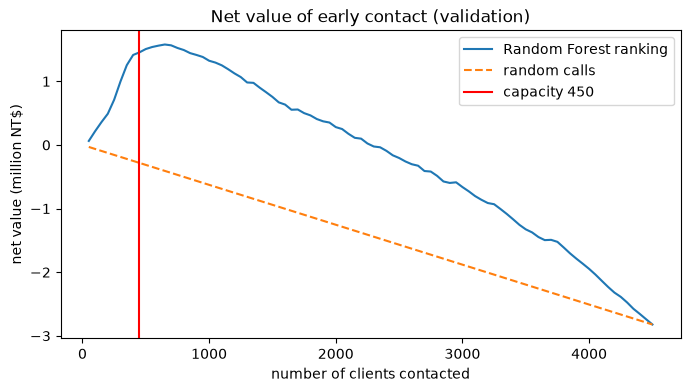

In [24]:
plt.figure(figsize=(8, 4))
plt.plot(k_values, value_model / 1e6, label=f'{best_model} ranking')
plt.plot(k_values, value_random / 1e6, '--', label='random calls')
plt.axvline(450, color='red', label='capacity 450')
plt.xlabel('number of clients contacted')
plt.ylabel('net value (million NT$)')
plt.title('Net value of early contact (validation)')
plt.legend()
plt.show()

Random calls lose money (-0.28 M NT$ for 450 calls) because 78% of the calls go to good clients.
With the Random Forest ranking the 450 calls bring **+1.46 M NT$**. The value continues to grow until about **650 calls**,
so the capacity of 450 is too small. A cheap solution: send automatic SMS reminders to clients ranked 451–650.

### Which variables are the most important?

In [25]:
from sklearn.inspection import permutation_importance

input_cols = raw_number_cols + category_cols
# we wrap the model so that the new ratios are recalculated when a raw column is shuffled
from sklearn.preprocessing import FunctionTransformer

def add_ratios(df):
    df = df.copy()
    limit = df['LIMIT_BAL'].clip(lower=1)
    df['UTIL_LAST'] = (df['BILL_AMT1'] / limit).clip(-1, 3)
    df['UTIL_AVG'] = (df[bill_cols].mean(axis=1) / limit).clip(-1, 3)
    paid = df[pay_amt[:5]].sum(axis=1)
    owed = df[bill_cols[1:]].clip(lower=0).sum(axis=1)
    ratio = paid / owed.where(owed > 0, 1)
    df['PAY_RATIO'] = ratio.where(owed > 0, 1.0).clip(0, 2)
    df['MONTHS_LATE'] = (df[pay_status] > 0).sum(axis=1)
    df['MAX_DELAY'] = df[pay_status].max(axis=1).clip(lower=0)
    df['BILL_TREND'] = ((df['BILL_AMT1'] - df['BILL_AMT6']) / limit).clip(-3, 3)
    df['ZERO_PAY_MONTHS'] = ((df[pay_amt].values == 0) & (df[bill_cols].values > 0)).sum(axis=1)
    return df

best_full = Pipeline([('ratios', FunctionTransformer(add_ratios)), ('model', models[best_model])])
perm = permutation_importance(best_full, valid[input_cols], y_valid, scoring='average_precision',
                              n_repeats=5, random_state=42)
importance = pd.Series(perm.importances_mean, index=input_cols).sort_values(ascending=False)
importance.head(8).round(4)

PAY_0        0.1759
BILL_AMT1    0.0229
PAY_2        0.0178
LIMIT_BAL    0.0162
PAY_AMT3     0.0077
PAY_5        0.0073
PAY_AMT1     0.0072
PAY_4        0.0070
dtype: float64

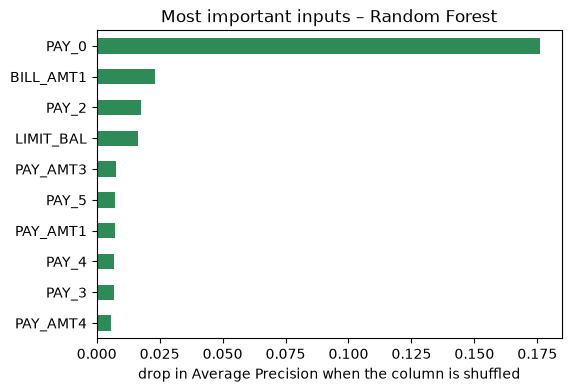

In [26]:
importance.head(10).sort_values().plot(kind='barh', figsize=(6, 4), color='seagreen')
plt.xlabel('drop in Average Precision when the column is shuffled')
plt.title(f'Most important inputs – {best_model}')
plt.show()

The payment status of September (`PAY_0`) is by far the most important input, then the September bill, the August status and the credit limit.
This makes sense for a bank: recent payment behaviour is the best signal.

## Task 7 – Final test (only once)
We fixed the model (**Random Forest**) and the policy (**call the top 450**) before looking at the test set.

In [27]:
final_model = models[best_model]
print('Final model:', best_model)
y_test = test['default'].values
test_scores = final_model.predict_proba(test[features])[:, 1]

predicted = (test_scores >= 0.50).astype(int)
print('Accuracy (0.50):  ', round(accuracy_score(y_test, predicted), 3))
print('ROC-AUC:          ', round(roc_auc_score(y_test, test_scores), 3))
print('Average Precision:', round(average_precision_score(y_test, test_scores), 3))

selected_rows = np.argsort(-test_scores, kind='stable')[:capacity]
found = y_test[selected_rows].sum()
print('defaulters found in top 450:', found)
print('false alerts:', capacity - found)
print('precision at 450:', round(found / capacity, 3))
print('recall at 450:', round(found / y_test.sum(), 3))

exposure_test = test['BILL_AMT1'].clip(lower=0).values
saved = recovery_rate * (exposure_test[selected_rows] * y_test[selected_rows]).sum()
print('net value (NT$):', round(saved - contact_cost * capacity - false_alarm_cost * (capacity - found)))

Final model: Random Forest
Accuracy (0.50):   0.817
ROC-AUC:           0.782
Average Precision: 0.556
defaulters found in top 450: 317
false alerts: 133
precision at 450: 0.704
recall at 450: 0.318
net value (NT$): 1789164


In [28]:
# file for the collections team: client ID + risk score, WITHOUT the real outcome
review = pd.DataFrame({
    'rank': np.arange(1, capacity + 1),
    'client_id': test['ID'].values[selected_rows],
    'risk_score': test_scores[selected_rows].round(4),
})
review.to_csv('Credit_Review_Top450.csv', index=False)
review.head(10)

,rank,client_id,risk_score
0,1,27537,0.9006
1,2,20722,0.8985
2,3,14951,0.8946
3,4,28748,0.8910
4,5,21961,0.8747
5,6,20255,0.8670
6,7,1147,0.8648
7,8,14862,0.8609
8,9,25054,0.8552
9,10,29727,0.8522


**Business interpretation.** We recommend the **Random Forest** with a **top-450 review policy**: every month the team calls the 450 clients with the highest risk score.
On the test set this list contains **317 real defaulters and 133 false alerts** (precision 70%), which is 3.2 times better than random calls,
with a ROC-AUC of 0.78, similar to validation, so the model does not overfit. With our cost assumptions this gives about **+1.79 M NT$** for 4,500 clients.
The limit is that 450 calls catch only 32% of all defaulters, so the bank should add cheap SMS reminders for the next clients in the ranking.
We must not use these test results to choose another model now: the test set would then become part of the selection and the result would be too optimistic.
Finally, the model predicts default but does not prove that a call prevents it; for that we would need an A/B test (call half of the high-risk clients and compare).

*Note: the model used by our website is trained by `src/train.py` with exactly the same settings.*